# GluCEST White Matter Ageing – Paper Figures

Recreates every figure and table in the manuscript, in order. Run top to bottom.
Without the data drive, the 3D figures are rebuilt from the saved renders in `assets_3d/`.
P18 excluded (n = 17, 10 repeat scans). Participants are numbered by age.

In [1]:
import io
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path
from PIL import Image as PILImage
from IPython.display import Image, display

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100

## 1 — Data drive and helpers

In [2]:
sys.path.insert(0, str(Path.cwd().parent))   # utils_main.py is one folder up
import utils_main as U
import figdata as D
import fig_hero_cover as H                   # H.ASSETS = saved 3D renders

HAVE_DRIVE = Path(U.BASE).exists() and Path(U.DATA_DIR).exists()
RECOMPOSE  = not HAVE_DRIVE                  # no drive -> rebuild 3D figures from saved renders
print('data drive found:', HAVE_DRIVE)

AGE = dict(D.subjects_by_age())


def show(name, w=1000, px=1800):
    # downscaled preview of the saved figure (full res is in name.png / name.pdf)
    im = PILImage.open(f'{name}.png').convert('RGB')
    im.thumbnail((px, 4 * px))
    buf = io.BytesIO()
    im.save(buf, 'PNG', optimize=True)
    display(Image(buf.getvalue(), width=w))


def show_render(name, title, w=420):
    # one 3D render on its own
    print(title)
    show(H.ASSETS / f'hero_{name}', w=w, px=600)

data drive found: True


## 2 — Figure 1: WM atlas, 24 mm slab and subregions (3D)

wmov white done


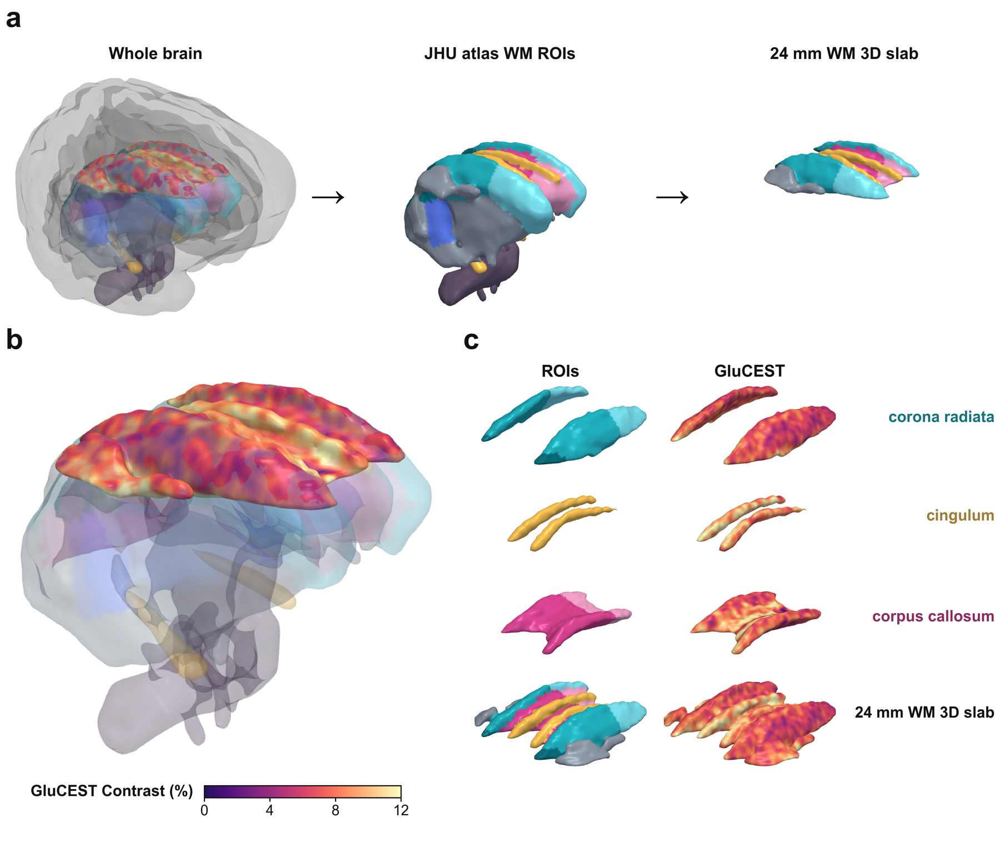

In [3]:
import fig_hero_gm as G
G.make(('wmov',), recompose=RECOMPOSE)
show('Fig_hero_WM_overview_v2_white')

a  whole brain


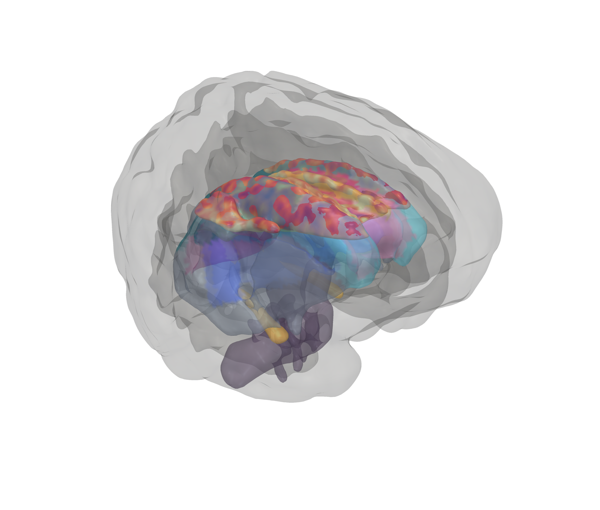

a  JHU atlas WM ROIs


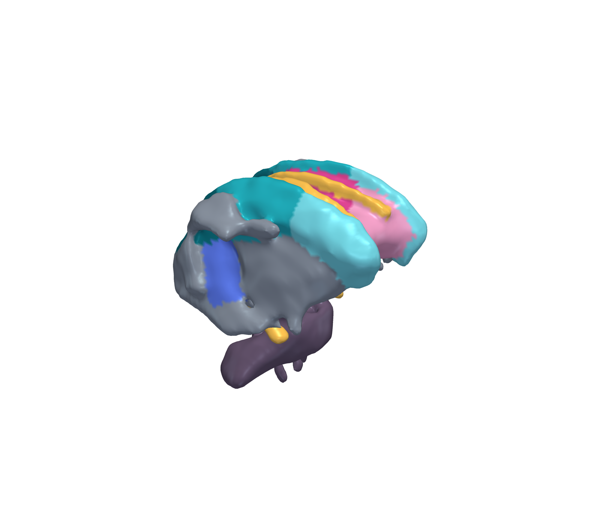

a  24 mm WM 3D slab


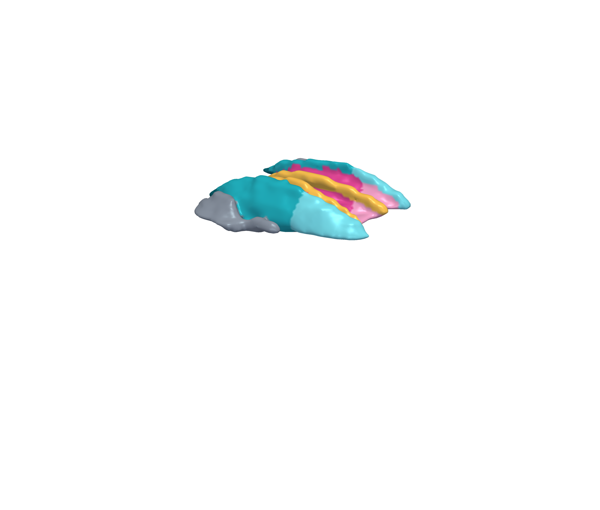

b  slab GluCEST in the brain


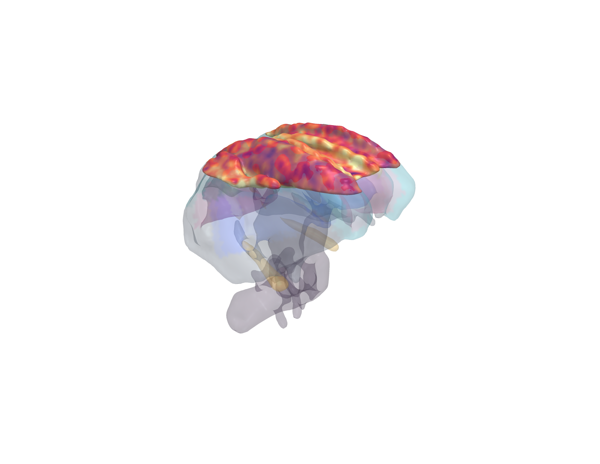

c  subregion ROIs (exploded)


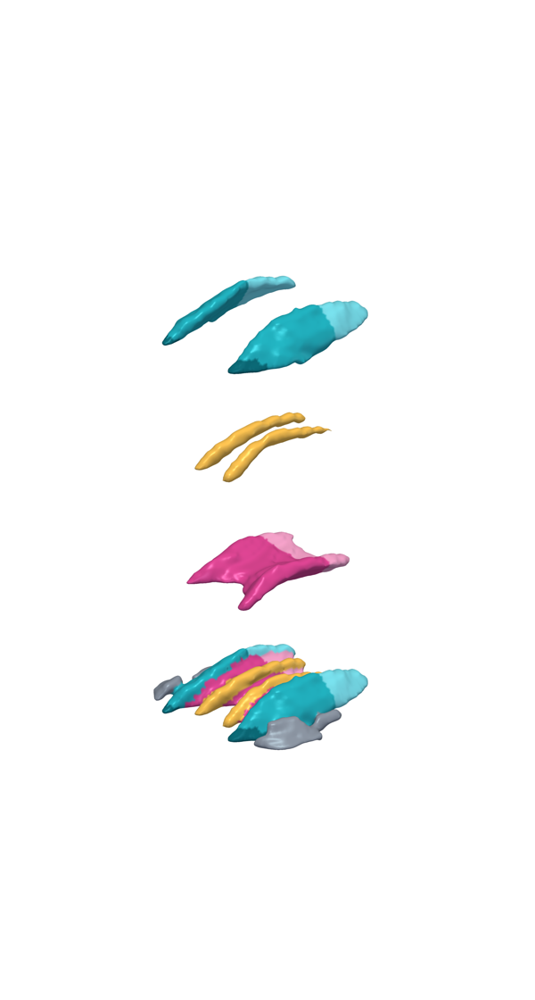

c  subregion GluCEST (exploded)


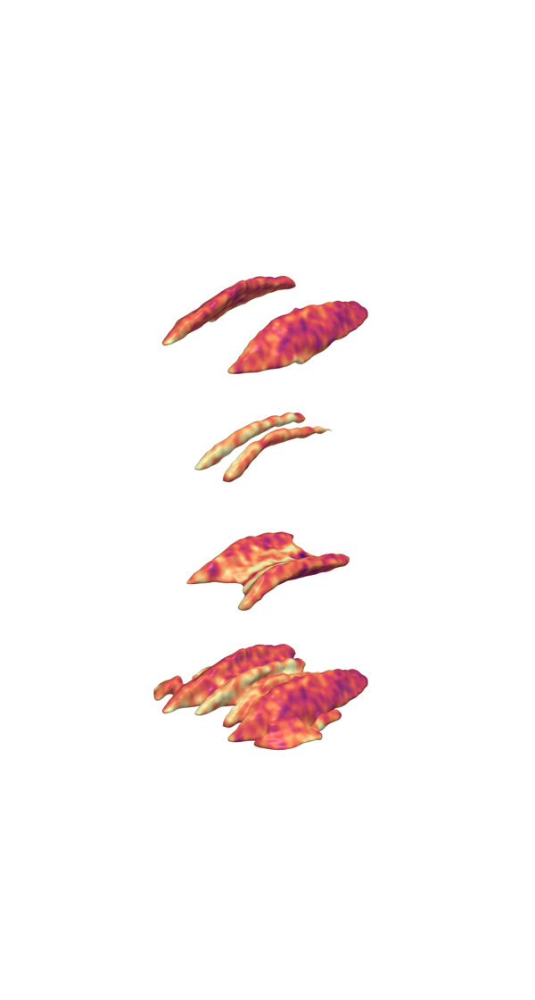

In [4]:
# Figure 1 elements
show_render('wmov_p0_white',   'a  whole brain')
show_render('wmov_p1_white',   'a  JHU atlas WM ROIs')
show_render('wmov_p2_white',   'a  24 mm WM 3D slab')
show_render('wmov_a_white',    'b  slab GluCEST in the brain')
show_render('wmov_bseg_white', 'c  subregion ROIs (exploded)')
show_render('wmov_bglu_white', 'c  subregion GluCEST (exploded)')

## 3 — Figure 2: scan–rescan maps and GM / WM GluCEST, young to old

saved Fig2_age_repeatability.pdf Fig2_age_repeatability.png


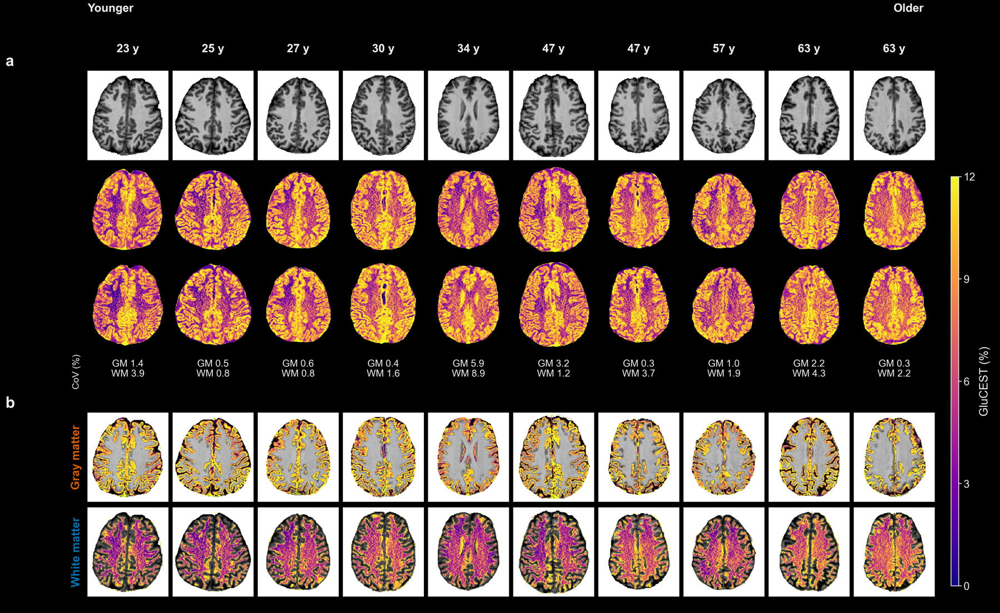

In [5]:
import fig2_age_repeatability as F2
F2.make()
show('Fig2_age_repeatability')

## 4 — Tables 1–3: scan–rescan CoV (%)

In [6]:
# Table 1: GM, WM and whole slab (whole slab = mean of the CSF, GM and WM means)
r = pd.read_csv('_cache/retest_means.csv')
for s in 'P13':
    r[f'WB_{s}'] = r[[f'CSF_{s}', f'GM_{s}', f'WM_{s}']].mean(axis=1)

t1 = pd.DataFrame({'Age':            r.Subject.map(AGE),
                   'GM CoV':         U.pct_cov(r.GM_A, r.GM_B),
                   'WM CoV':         U.pct_cov(r.WM_A, r.WM_B),
                   'Whole-slab CoV': U.pct_cov(r.WB_A, r.WB_B)}).sort_values('Age', kind='stable')
t1.index = range(1, len(t1) + 1)
t1.loc['Mean'] = t1.mean()
t1.round(2).to_csv('Table1_GM_WM_wholeslab_CoV.csv')
t1.round(2)

,Age,GM CoV,WM CoV,Whole-slab CoV
1,23.0,1.41,3.91,1.27
2,25.0,0.52,0.82,0.63
3,27.0,0.63,0.80,1.03
4,30.0,0.40,1.59,0.98
5,34.0,5.85,8.89,7.74
6,47.0,3.17,1.17,3.52
7,47.0,0.27,3.66,1.22
8,57.0,1.04,1.89,0.45
9,63.0,2.19,4.26,3.37
10,63.0,0.32,2.17,0.20


In [7]:
# Tables 2 and 3 come from recompute_retest_tables.py (needs the data drive, ~5 min)
# Table 2: WM tracts, CC split into genu / body / splenium
# Table 3: GM lobes (temporal and insula are in the slab for only 1-2 subjects, so dropped)
REEXTRACT = False   # True to re-extract from the raw scans
if REEXTRACT:
    import recompute_retest_tables as RT
    RT.main()

t2 = pd.read_csv('Table2_WM_subregion_CoV_split.csv', index_col=0)
t3 = pd.read_csv('Table3_GM_lobe_CoV.csv', index_col=0)
t2 = t2[['Age', 'CC genu', 'CC body', 'CC splenium', 'CC (all)', 'Cingulum', 'CC + Cing.', 'CR', 'LF', 'FOF']]
t3 = t3[['Age', 'Frontal', 'Cingulate', 'Parietal', 'Occipital', 'All GM regions']]
display(t2)
display(t3)

,Age,CC genu,CC body,CC splenium,CC (all),Cingulum,CC + Cing.,CR,LF,FOF
Participant,,,,,,,,,,
1,23.0,23.87,1.90,0.58,0.38,0.36,0.44,3.74,4.85,18.75
2,25.0,14.62,2.14,0.69,3.05,1.99,2.93,2.01,2.17,9.02
3,27.0,15.50,4.03,1.40,4.00,1.10,3.59,1.88,0.91,0.21
4,30.0,0.10,1.55,NaN,1.54,1.51,0.86,1.16,1.52,0.75
5,34.0,3.98,7.36,12.58,7.99,7.29,7.88,10.28,10.21,9.98
6,47.0,3.58,2.10,0.38,1.01,9.14,1.25,5.43,3.35,6.25
7,47.0,4.13,11.90,8.73,9.99,7.44,5.26,0.79,2.05,0.08
8,57.0,4.61,2.51,3.79,2.56,10.29,4.82,0.74,2.64,6.78
9,63.0,4.25,10.81,9.15,10.07,5.84,9.12,7.37,3.75,10.63


,Age,Frontal,Cingulate,Parietal,Occipital,All GM regions
Participant,,,,,,
1,23.0,2.27,0.67,5.98,5.46,1.44
2,25.0,0.38,1.09,0.67,1.30,0.41
3,27.0,1.47,1.12,0.72,0.45,0.58
4,30.0,0.23,1.81,1.48,1.54,0.47
5,34.0,4.89,6.02,7.78,4.46,6.02
6,47.0,1.18,4.69,1.44,2.75,0.09
7,47.0,2.14,4.38,4.90,4.70,3.69
8,57.0,0.87,0.47,1.54,2.53,1.17
9,63.0,2.47,2.07,1.51,1.37,1.96


In [8]:
# genu and splenium are only partly in the slab -> fewer voxels, noisier CoV
rt = pd.read_csv('_cache/subregion_retest.csv').query("Variant == 'raw'")
rt.groupby('Subregion').n_vox.median().sort_values()

Subregion
EC               14.0
ALIC             75.0
sFOF            184.0
CC splenium     277.0
CC genu         790.5
PCR            1050.0
Cingulum       1430.5
ACR            1485.0
SLF            2767.5
SCR            4167.0
CC body        4643.5
Name: n_vox, dtype: float64

## 5 — Figure 3: GluCEST vs age by tissue

saved Fig3_age_trends.pdf Fig3_age_trends.png


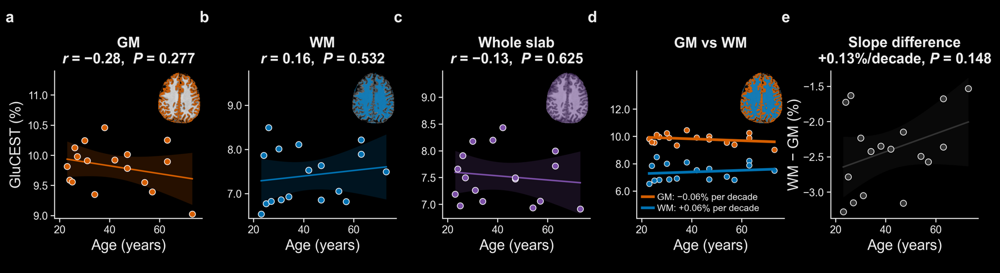

,Tissue,n,r,P,slope_per_decade
0,GM,17,-0.280,0.277,-0.065
1,WM,17,0.163,0.532,0.063
2,Whole slab,17,-0.128,0.625,-0.039
3,WM - GM,17,0.366,0.148,0.128


In [9]:
import paper_figures as P
P.fig3()
show('Fig3_age_trends')
pd.read_csv('stats_Fig3_age_trends.csv').round(3)

## 6 — Figure 4: CC + cingulum vs corona radiata (3D)

{'Corpus callosum': np.float64(-0.022), 'Cingulum': np.float64(0.001), 'CC + cingulum': np.float64(-0.027), 'Corona radiata': np.float64(0.131), 'diff': np.float64(0.158)} diff P 0.0176 mixed (np.float64(0.15810513523815714), np.float64(0.007674179836616247))


saved Fig4_3D_WM_divergence.pdf Fig4_3D_WM_divergence.png


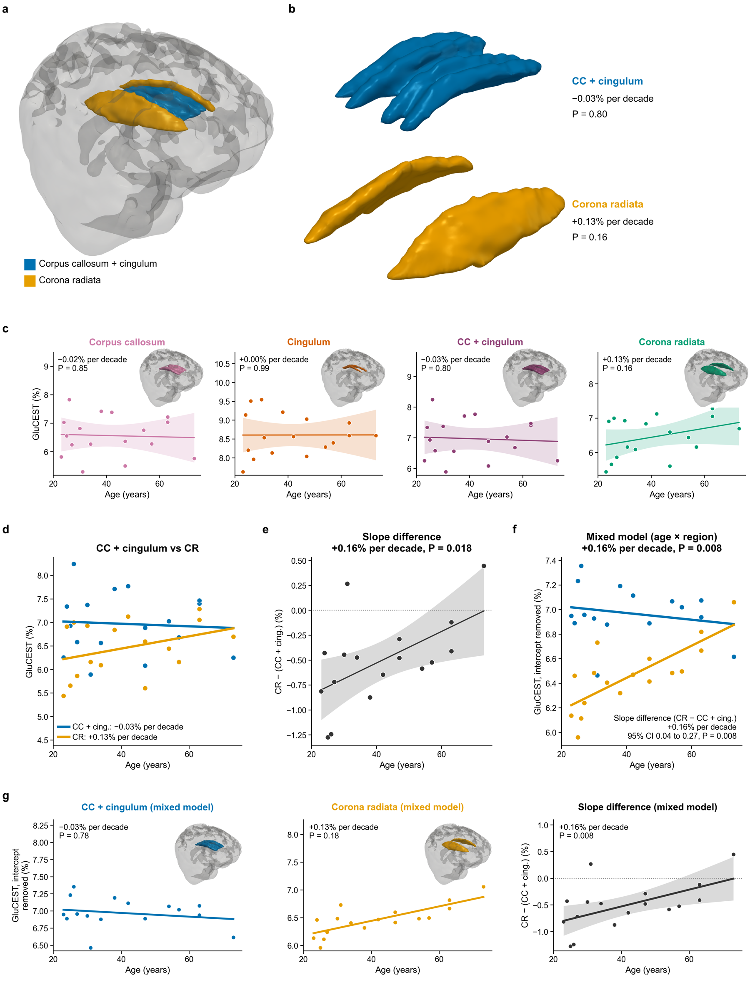

In [10]:
import fig4_3d as F4
st, mm, ms = F4.main(recompose=RECOMPOSE)
show('Fig4_3D_WM_divergence', w=800)

a  CC + cingulum (blue) and corona radiata (yellow)


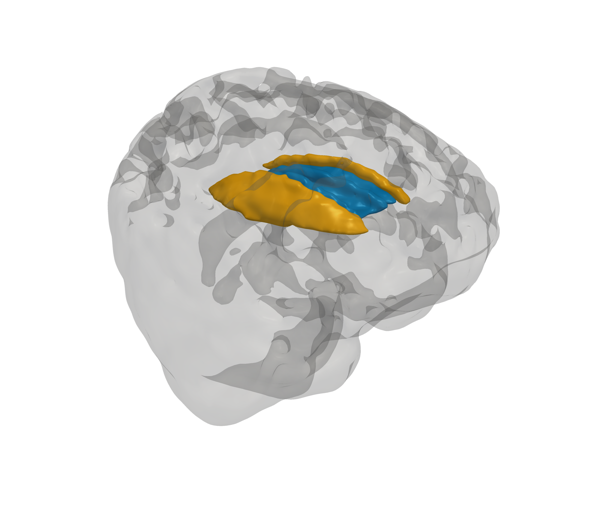

b  exploded view


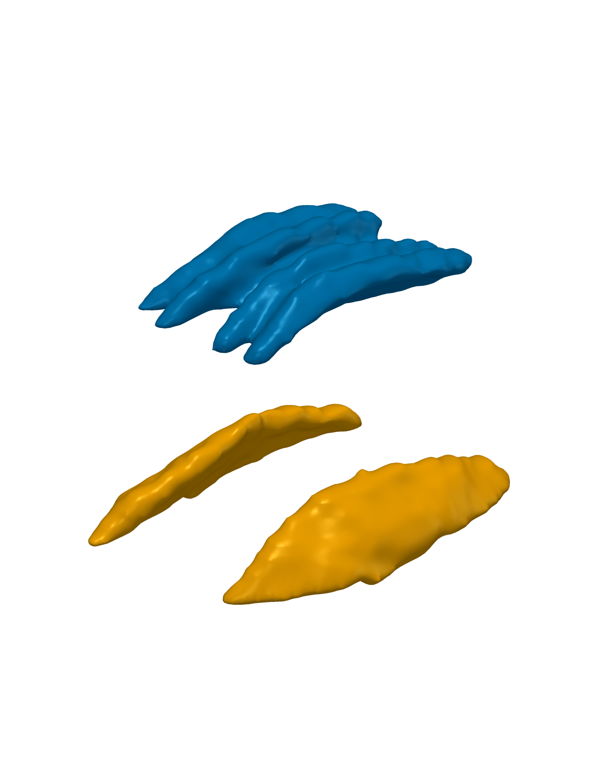

c  corpus callosum


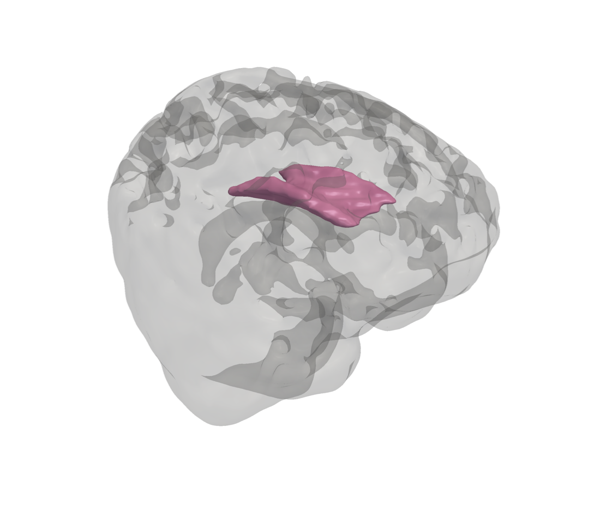

c  cingulum


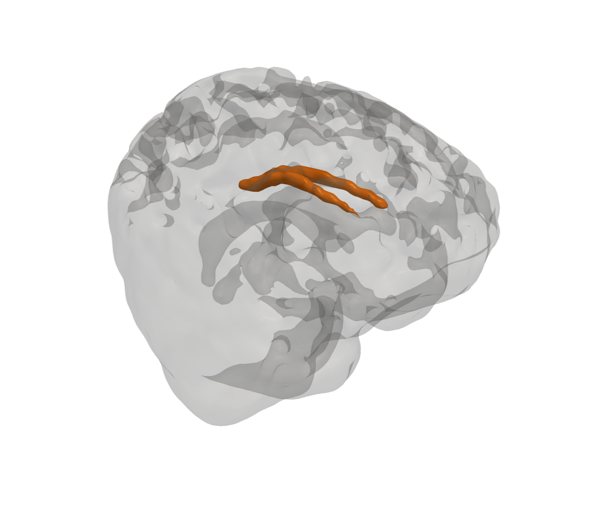

c  CC + cingulum


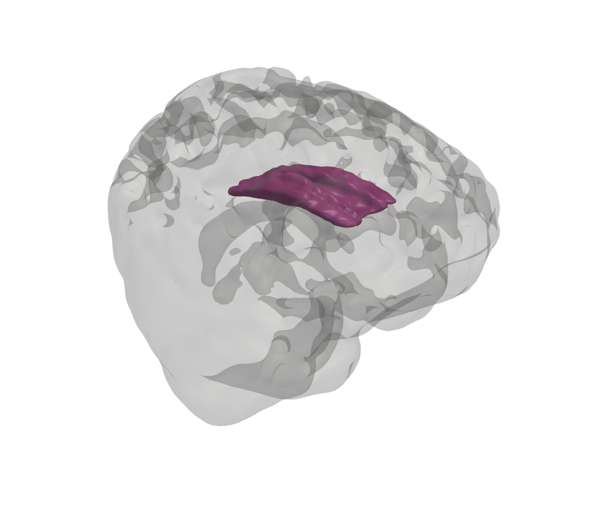

c  corona radiata


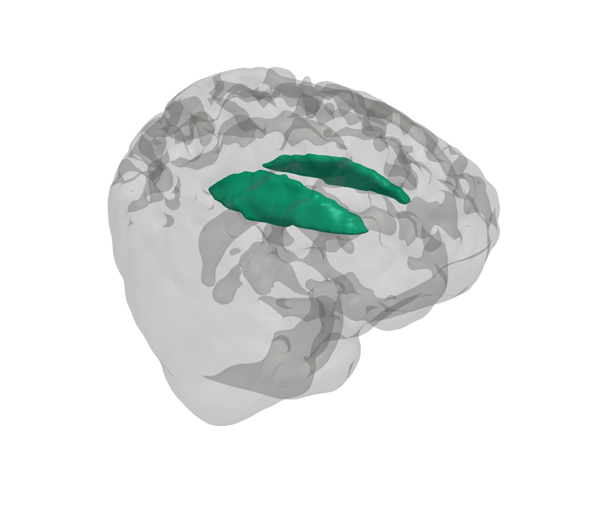

g  CC + cingulum (mixed model)


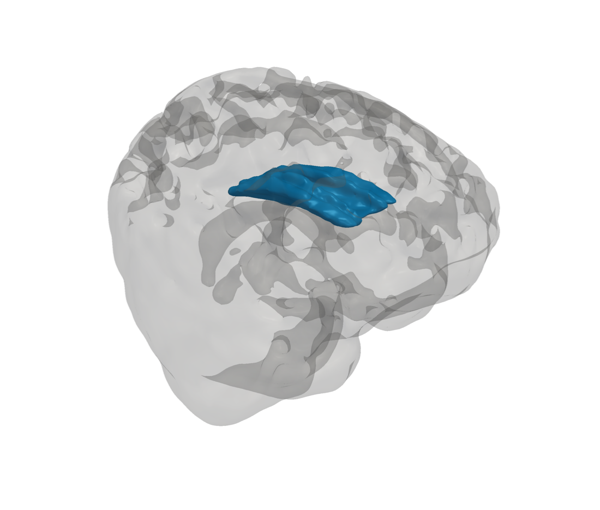

g  corona radiata (mixed model)


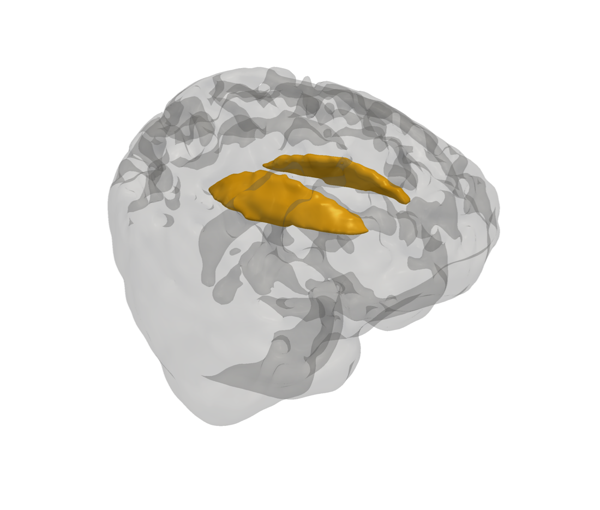

In [11]:
# Figure 4 elements
show_render('fig4_3d_a',       'a  CC + cingulum (blue) and corona radiata (yellow)', w=500)
show_render('fig4_3d_b',       'b  exploded view', w=500)
show_render('fig4_3d_t_ccl',   'c  corpus callosum')
show_render('fig4_3d_t_cing',  'c  cingulum')
show_render('fig4_3d_t_cc',    'c  CC + cingulum')
show_render('fig4_3d_t_cr',    'c  corona radiata')
show_render('fig4_3d_tb_cc',   'g  CC + cingulum (mixed model)')
show_render('fig4_3d_tb_cr',   'g  corona radiata (mixed model)')

## 7 — Slope difference and mixed model

In [12]:
# within-subject difference D = CR - (CC + cing); its age slope = slope_CR - slope_CC, P tests if they differ
# mixed model: GluCEST ~ age * region + (1 | subject); the age:region term is the same slope difference
from fig_wm_subregions_age import PARTS, part_means, slope_stats

sub = D.subregions('raw')
pm  = part_means(sub[sub.Subregion.isin(sum(PARTS.values(), []))])
age = pm.Age.values.astype(float)

rows = []
for mid in ['CC + cingulum', 'Corpus callosum']:      # CC alone = sensitivity check
    d  = slope_stats(age, pm['Corona radiata'] - pm[mid])
    lg = pm.melt(id_vars=['Subject', 'Age'], value_vars=[mid, 'Corona radiata'], var_name='Region', value_name='G')
    lg['CR'] = (lg.Region == 'Corona radiata').astype(int)
    m  = smf.mixedlm('G ~ Age * CR', lg, groups='Subject').fit(reml=True)
    rows.append({'Comparison':        f'CR vs {mid}',
                 'Midline slope':     slope_stats(age, pm[mid])['slope'],
                 'CR slope':          slope_stats(age, pm['Corona radiata'])['slope'],
                 'Slope diff (OLS)':  d['slope'],
                 'P (OLS)':           d['P'],
                 'Slope diff (LMM)':  10 * m.params['Age:CR'],
                 'P (LMM)':           m.pvalues['Age:CR']})

pd.DataFrame(rows).set_index('Comparison').round(3)   # slopes in % per decade

,Midline slope,CR slope,Slope diff (OLS),P (OLS),Slope diff (LMM),P (LMM)
Comparison,,,,,,
CR vs CC + cingulum,-0.027,0.131,0.158,0.018,0.158,0.008
CR vs Corpus callosum,-0.022,0.131,0.153,0.045,0.153,0.029


In [13]:
# does GluCEST tell you age beyond T1? compare age ~ T1 with age ~ T1 + GluCEST
tm = D.tissue_means()
for t in ['GM', 'WM']:
    g    = tm[tm.Tissue == t]
    full = smf.ols('Age ~ T1 + GluCEST', g).fit()
    dr2  = full.rsquared - smf.ols('Age ~ T1', g).fit().rsquared
    print(f'{t}: delta R2 = {dr2:.3f}, p = {full.pvalues["GluCEST"]:.3f}')

GM: delta R2 = 0.207, p = 0.024
WM: delta R2 = 0.000, p = 0.967


## 8 — Supplementary: B0 and B1 maps, scan 1 vs scan 2

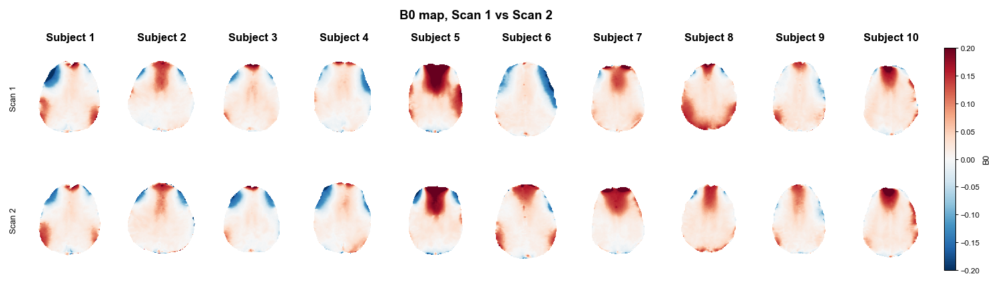

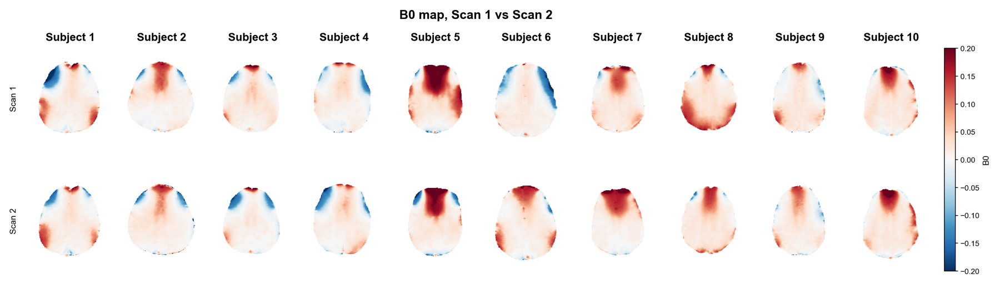

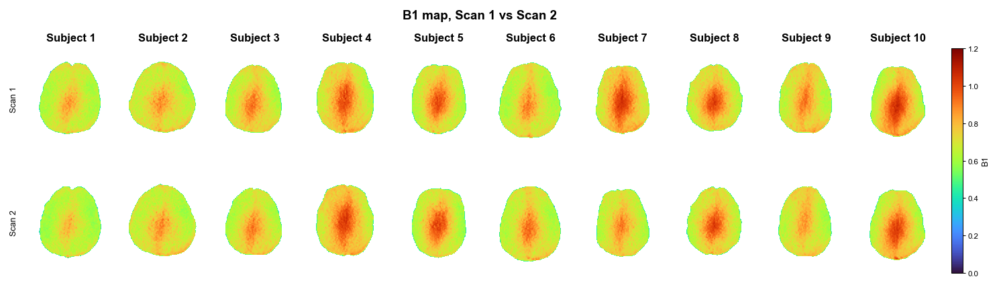

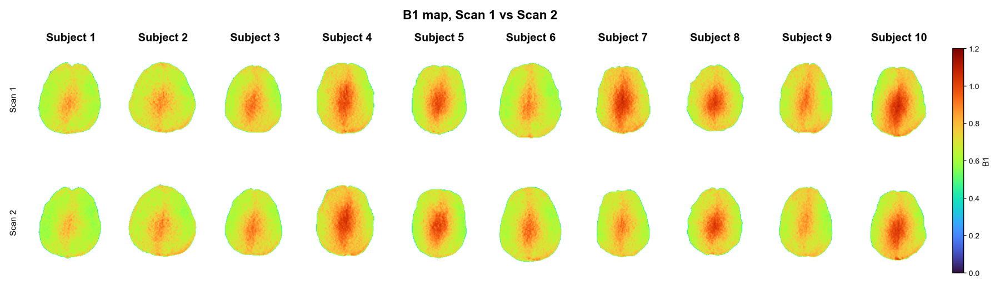

In [14]:
import supp_figures as SF
for kind in ['B0', 'B1']:
    if HAVE_DRIVE:
        SF.field_maps(kind)
    show(f'Supp_Fig_{kind}_maps')

## 9 — Supplementary: GM lobes, 24 mm slab (3D)

gmov white done


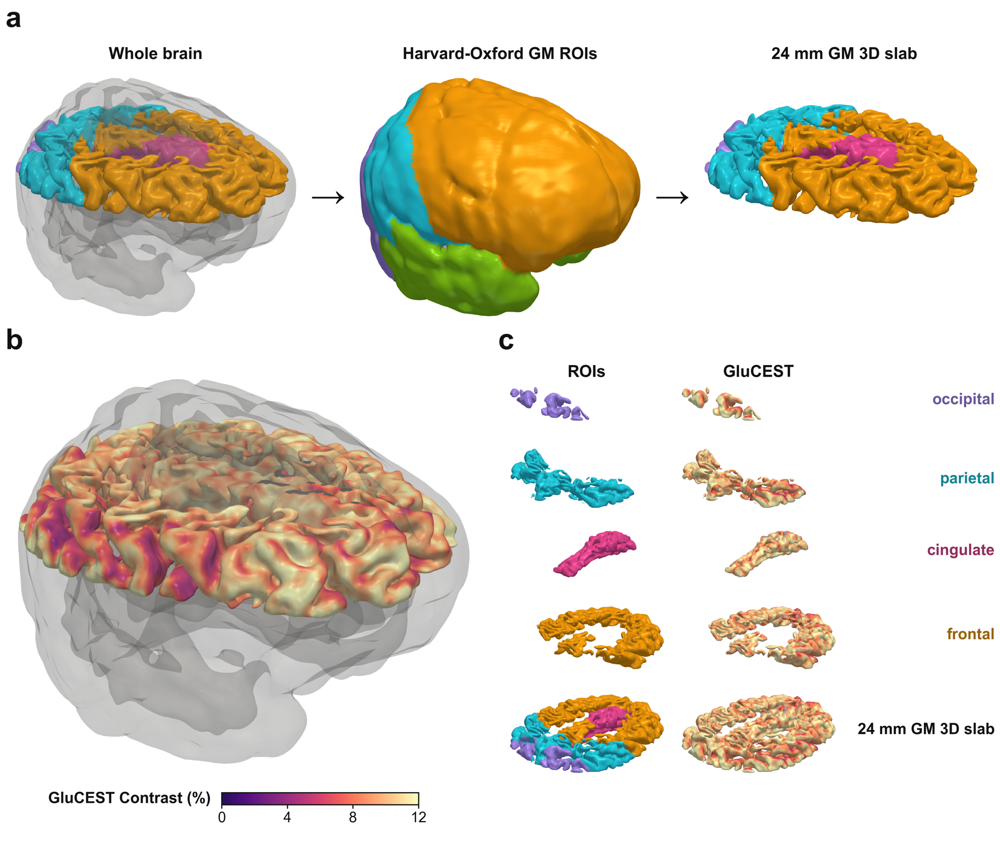

In [15]:
G.make(('gmov',), recompose=RECOMPOSE)
show('Fig_hero_GM_overview_v2_white')

a  whole brain, slab GM ROIs


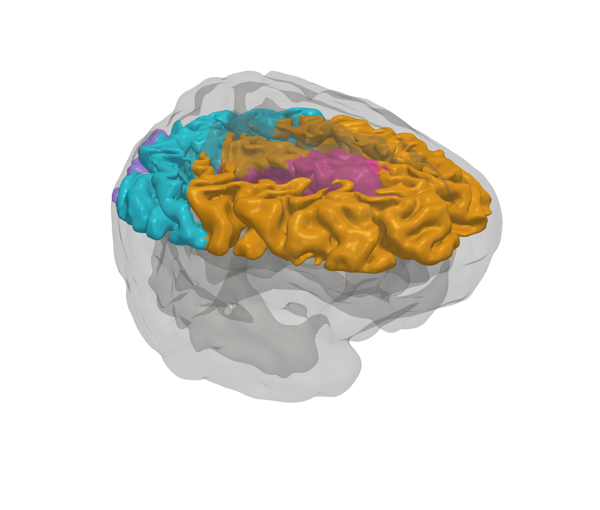

a  Harvard-Oxford GM ROIs


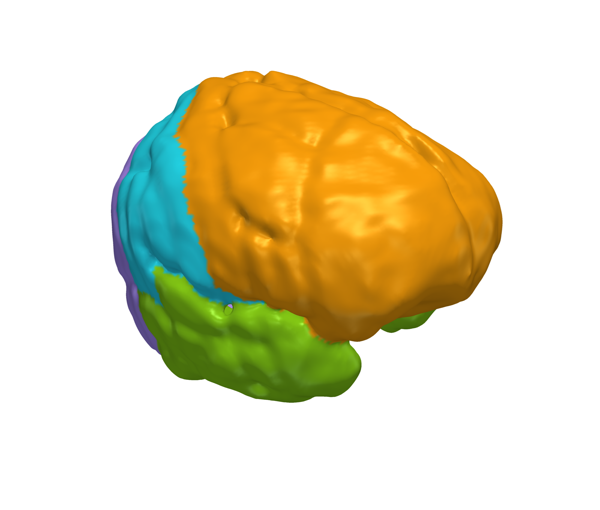

a  24 mm GM 3D slab


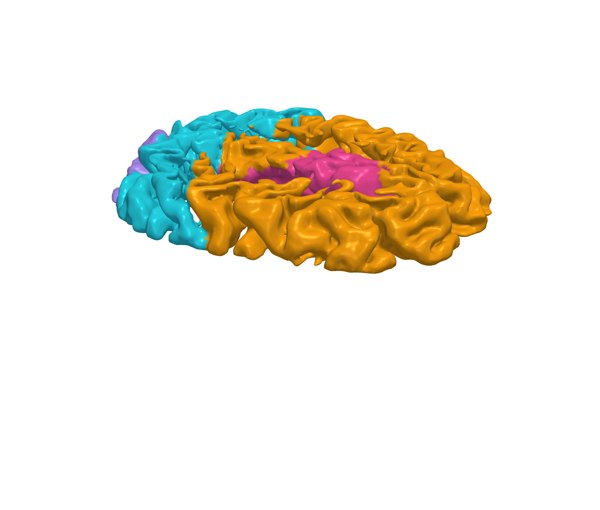

b  slab GM GluCEST in the brain


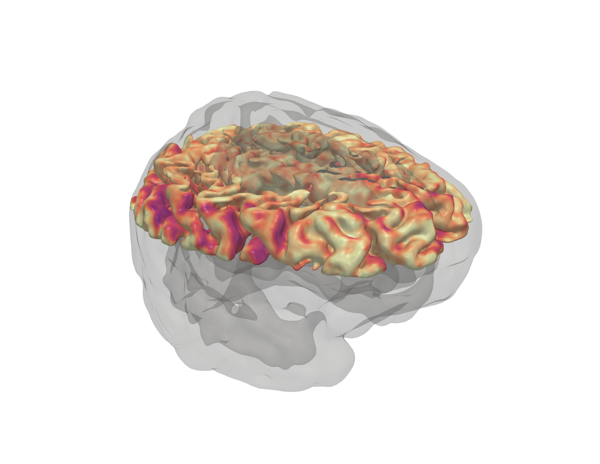

c  lobe ROIs (exploded)


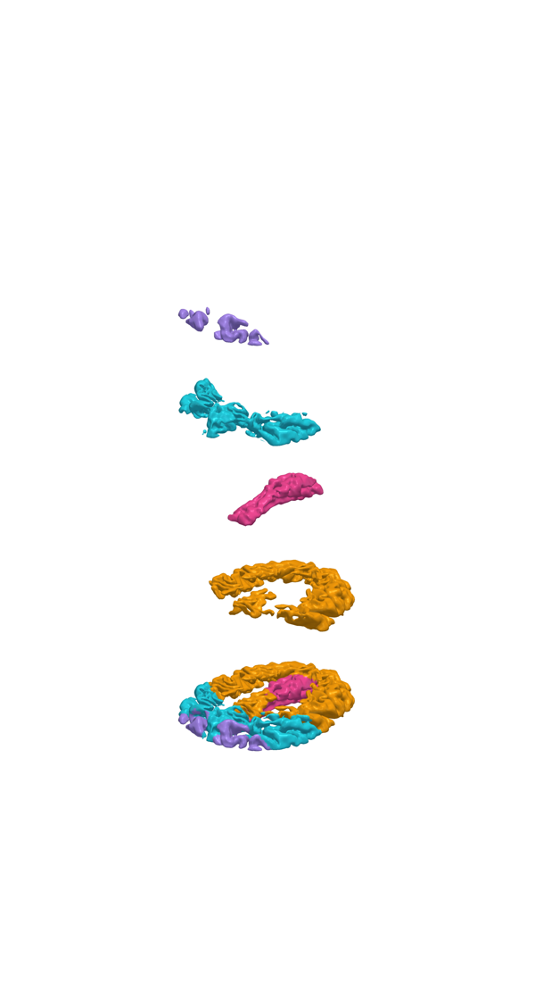

c  lobe GluCEST (exploded)


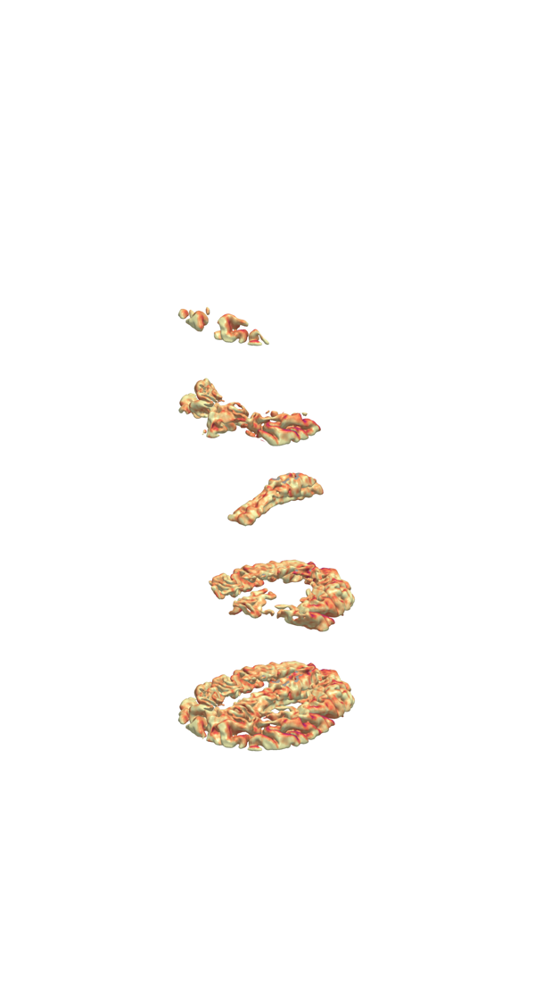

In [16]:
# GM overview elements
show_render('gmov_p0_white',   'a  whole brain, slab GM ROIs')
show_render('gmov_p1_white',   'a  Harvard-Oxford GM ROIs')
show_render('gmov_p2_white',   'a  24 mm GM 3D slab')
show_render('gmov_a_white',    'b  slab GM GluCEST in the brain')
show_render('gmov_bseg_white', 'c  lobe ROIs (exploded)')
show_render('gmov_bglu_white', 'c  lobe GluCEST (exploded)')